# Project Name : Premium prediction for Health insurance

In [206]:
# ML Project Pipeline
# Data Loading -> Understand Data (EDA) -> Data Cleaning -> Train ML model -> Deploy model

In [207]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Task-1 : Data Loading

In [208]:
df = pd.read_excel("premiums.xlsx")
df

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,24,Female,Northwest,Unmarried,0,Underweight,No Smoking,Self-Employed,25L - 40L,35,No Disease,Bronze,9111
49996,47,Female,Southeast,Married,2,Normal,No Smoking,Salaried,> 40L,82,Thyroid,Gold,27076
49997,21,Male,Northwest,Unmarried,0,Normal,Regular,Freelancer,25L - 40L,32,No Disease,Bronze,8564
49998,18,Male,Northwest,Unmarried,2,Normal,No Smoking,Salaried,10L - 25L,20,No Disease,Bronze,9490


In [209]:
df.shape

(50000, 13)

In [210]:
df.columns

Index(['Age', 'Gender', 'Region', 'Marital_status', 'Number Of Dependants',
       'BMI_Category', 'Smoking_Status', 'Employment_Status', 'Income_Level',
       'Income_Lakhs', 'Medical History', 'Insurance_Plan',
       'Annual_Premium_Amount'],
      dtype='str')

In [211]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Age                    50000 non-null  int64
 1   Gender                 50000 non-null  str  
 2   Region                 50000 non-null  str  
 3   Marital_status         50000 non-null  str  
 4   Number Of Dependants   50000 non-null  int64
 5   BMI_Category           50000 non-null  str  
 6   Smoking_Status         49989 non-null  str  
 7   Employment_Status      49998 non-null  str  
 8   Income_Level           49987 non-null  str  
 9   Income_Lakhs           50000 non-null  int64
 10  Medical History        50000 non-null  str  
 11  Insurance_Plan         50000 non-null  str  
 12  Annual_Premium_Amount  50000 non-null  int64
dtypes: int64(4), str(9)
memory usage: 5.0 MB


# Handling Null values

In [212]:
df.isnull().sum()

Age                       0
Gender                    0
Region                    0
Marital_status            0
Number Of Dependants      0
BMI_Category              0
Smoking_Status           11
Employment_Status         2
Income_Level             13
Income_Lakhs              0
Medical History           0
Insurance_Plan            0
Annual_Premium_Amount     0
dtype: int64

In [213]:
df.dropna(inplace = True)

In [214]:
df.isnull().sum()

Age                      0
Gender                   0
Region                   0
Marital_status           0
Number Of Dependants     0
BMI_Category             0
Smoking_Status           0
Employment_Status        0
Income_Level             0
Income_Lakhs             0
Medical History          0
Insurance_Plan           0
Annual_Premium_Amount    0
dtype: int64

In [215]:
df.shape

(49976, 13)

# Handling Duplicate records

In [216]:
df.duplicated().sum()

np.int64(0)

In [217]:
# describe the statistical information about the data
df.describe()

,Age,Number Of Dependants,Income_Lakhs,Annual_Premium_Amount
count,49976.000000,49976.000000,49976.000000,49976.000000
mean,34.591764,1.711842,23.021150,15766.810189
std,15.000378,1.498195,24.221794,8419.995271
min,18.000000,-3.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8607.750000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22273.500000
max,356.000000,5.000000,930.000000,43471.000000


# Handling the inconsistant data

In [218]:
# Handle number of dependents

# Query : Print all the records where number of depencent < 0

df[df["Number Of Dependants"] < 0]

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
402,23,Female,Southwest,Unmarried,-3,Underweight,No Smoking,Freelancer,10L - 25L,18,No Disease,Silver,9309
2245,18,Male,Southwest,Unmarried,-3,Overweight,No Smoking,Freelancer,25L - 40L,28,No Disease,Silver,8095
2323,19,Male,Northwest,Unmarried,-3,Underweight,No Smoking,Freelancer,25L - 40L,40,No Disease,Bronze,4641
2986,34,Female,Southeast,Married,-1,Underweight,Regular,Self-Employed,25L - 40L,35,High blood pressure & Heart disease,Silver,22995
3756,41,Male,Southwest,Married,-1,Obesity,Regular,Salaried,10L - 25L,21,Diabetes,Silver,22766
...,...,...,...,...,...,...,...,...,...,...,...,...,...
48062,23,Male,Northwest,Unmarried,-1,Normal,No Smoking,Freelancer,> 40L,54,No Disease,Gold,13601
48086,36,Female,Southwest,Married,-1,Obesity,Occasional,Salaried,<10L,3,Diabetes,Bronze,14422
49256,60,Female,Southwest,Married,-1,Normal,No Smoking,Self-Employed,10L - 25L,21,Thyroid,Bronze,10141
49270,34,Male,Southeast,Married,-1,Obesity,No Smoking,Self-Employed,10L - 25L,17,Diabetes & Thyroid,Silver,21816


In [219]:
df[df["Number Of Dependants"] < 0]["Number Of Dependants"].unique()

array([-3, -1])

In [220]:
# convert the negative value to positive 
df["Number Of Dependants"] = df["Number Of Dependants"].abs()

In [221]:
df.describe()

,Age,Number Of Dependants,Income_Lakhs,Annual_Premium_Amount
count,49976.000000,49976.000000,49976.000000,49976.000000
mean,34.591764,1.717284,23.021150,15766.810189
std,15.000378,1.491953,24.221794,8419.995271
min,18.000000,0.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8607.750000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22273.500000
max,356.000000,5.000000,930.000000,43471.000000


# Handling the outliers

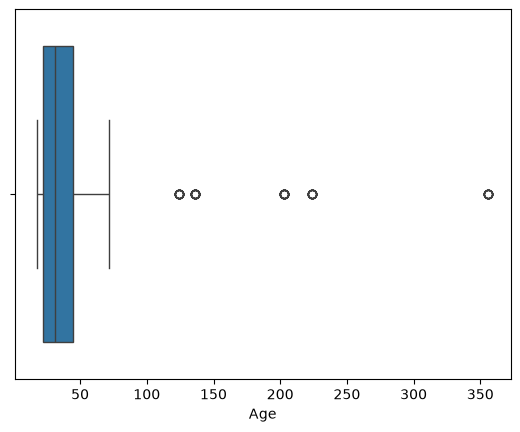

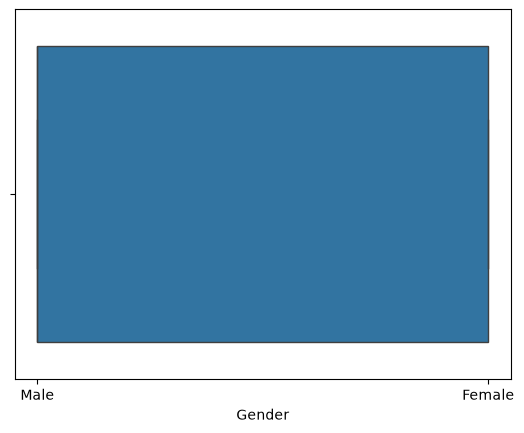

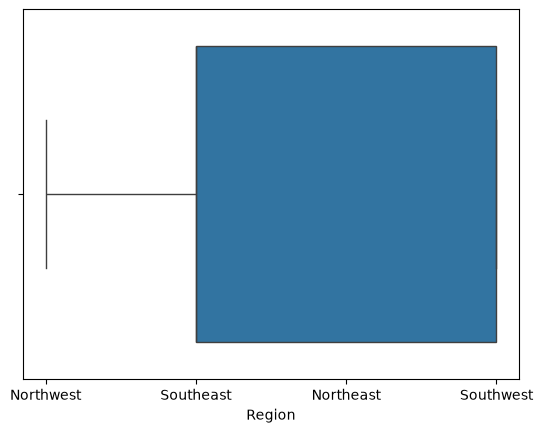

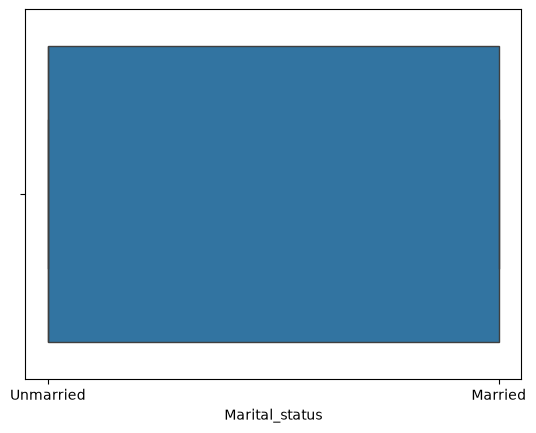

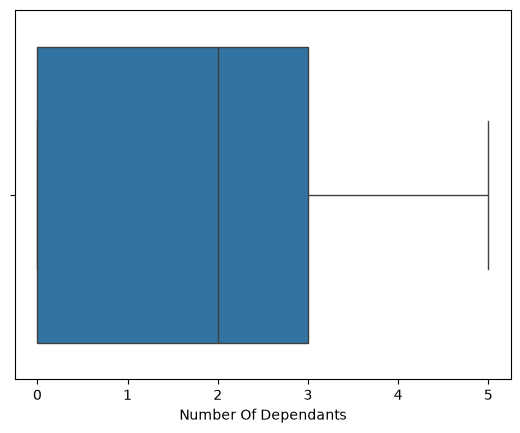

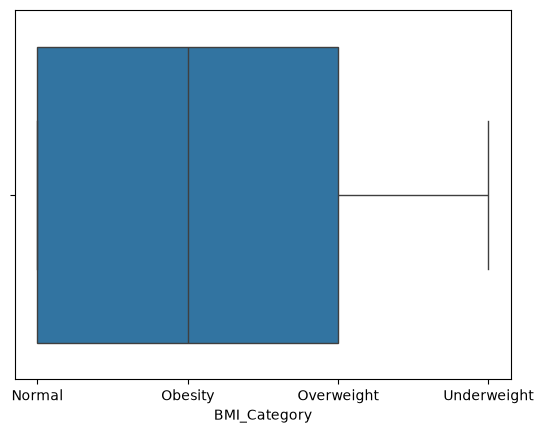

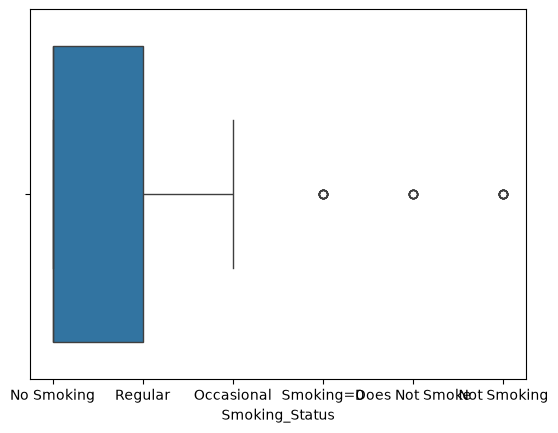

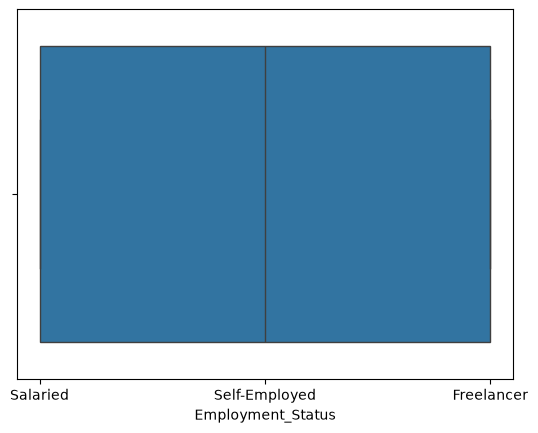

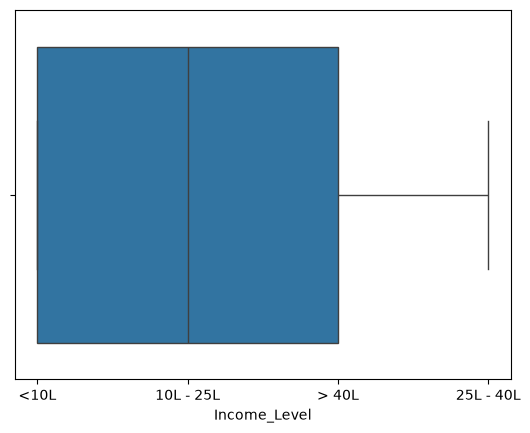

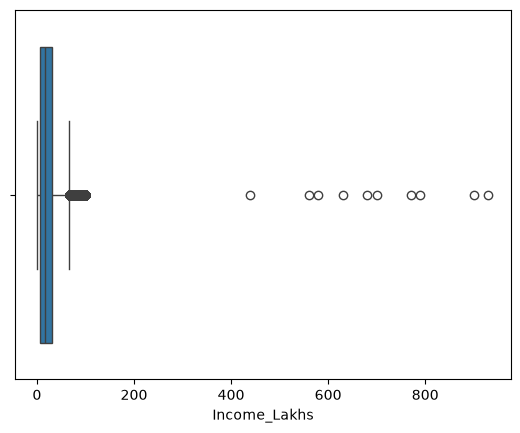

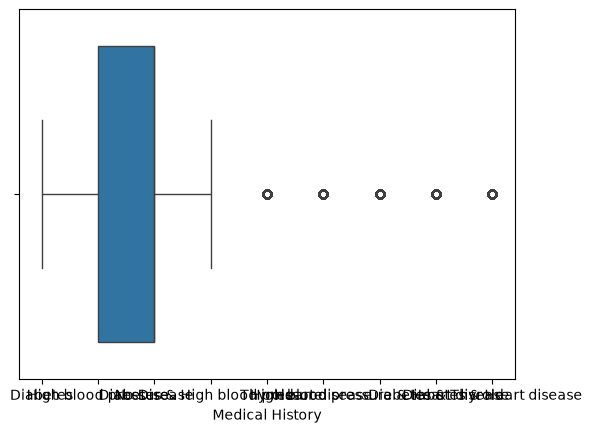

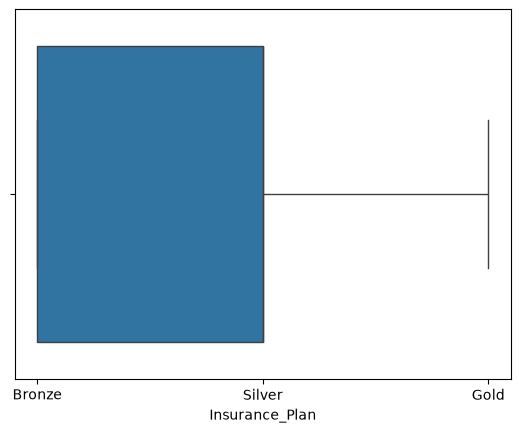

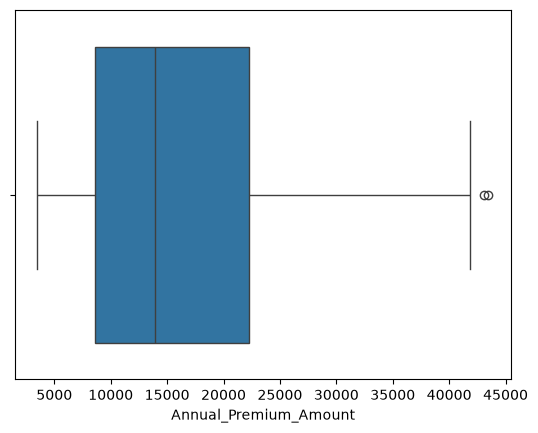

In [222]:
for col in df.columns:
    sns.boxplot(x = df[col])
    plt.show()

In [223]:
# Handle the outlier in Age column

# Query : Find the records where Age > 100
df[df.Age > 100].shape

(58, 13)

In [224]:
df[df.Age > 100].Age.unique()

array([224, 124, 136, 203, 356])

In [225]:
median = df.Age.median()
median

np.float64(31.0)

In [226]:
df.loc[df.Age > 100, "Age"] = median

In [227]:
df[df.Age > 100].sum()

Age                      0
Gender                    
Region                    
Marital_status            
Number Of Dependants     0
BMI_Category              
Smoking_Status            
Employment_Status         
Income_Level              
Income_Lakhs             0
Medical History           
Insurance_Plan            
Annual_Premium_Amount    0
dtype: object

In [228]:
# Find the number of records where income > 100 (1cr)
df[df.Income_Lakhs > 100].Income_Lakhs.count()

np.int64(10)

In [229]:
df[df.Income_Lakhs > 100].Income_Lakhs.unique()

array([560, 440, 630, 900, 930, 580, 700, 790, 770, 680])

In [230]:
# delete the records where income > 100
# Keeping those records where the income <= 100
df = df[df.Income_Lakhs <= 100]

In [231]:
df[df.Income_Lakhs > 100].Income_Lakhs.count()

np.int64(0)

In [232]:
df.describe()

,Age,Number Of Dependants,Income_Lakhs,Annual_Premium_Amount
count,49966.000000,49966.000000,49966.000000,49966.000000
mean,34.397630,1.717308,22.886063,15765.961574
std,13.674151,1.491911,22.166488,8419.532784
min,18.000000,0.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8607.250000
50%,31.000000,2.000000,17.000000,13928.000000
75%,45.000000,3.000000,31.000000,22272.000000
max,72.000000,5.000000,100.000000,43471.000000


In [233]:
df.info()

<class 'pandas.DataFrame'>
Index: 49966 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Age                    49966 non-null  int64
 1   Gender                 49966 non-null  str  
 2   Region                 49966 non-null  str  
 3   Marital_status         49966 non-null  str  
 4   Number Of Dependants   49966 non-null  int64
 5   BMI_Category           49966 non-null  str  
 6   Smoking_Status         49966 non-null  str  
 7   Employment_Status      49966 non-null  str  
 8   Income_Level           49966 non-null  str  
 9   Income_Lakhs           49966 non-null  int64
 10  Medical History        49966 non-null  str  
 11  Insurance_Plan         49966 non-null  str  
 12  Annual_Premium_Amount  49966 non-null  int64
dtypes: int64(4), str(9)
memory usage: 5.3 MB


In [234]:
# Segregating categorical columns
categorical_columns = df.select_dtypes(include = ['str']).columns
categorical_columns

Index(['Gender', 'Region', 'Marital_status', 'BMI_Category', 'Smoking_Status',
       'Employment_Status', 'Income_Level', 'Medical History',
       'Insurance_Plan'],
      dtype='str')

In [235]:
for col in categorical_columns:
    print(col, ":", df[col].unique())

Gender : <StringArray>
['Male', 'Female']
Length: 2, dtype: str
Region : <StringArray>
['Northwest', 'Southeast', 'Northeast', 'Southwest']
Length: 4, dtype: str
Marital_status : <StringArray>
['Unmarried', 'Married']
Length: 2, dtype: str
BMI_Category : <StringArray>
['Normal', 'Obesity', 'Overweight', 'Underweight']
Length: 4, dtype: str
Smoking_Status : <StringArray>
[    'No Smoking',        'Regular',     'Occasional',      'Smoking=0',
 'Does Not Smoke',    'Not Smoking']
Length: 6, dtype: str
Employment_Status : <StringArray>
['Salaried', 'Self-Employed', 'Freelancer']
Length: 3, dtype: str
Income_Level : <StringArray>
['<10L', '10L - 25L', '> 40L', '25L - 40L']
Length: 4, dtype: str
Medical History : <StringArray>
[                           'Diabetes',                 'High blood pressure',
                          'No Disease',      'Diabetes & High blood pressure',
                             'Thyroid',                       'Heart disease',
 'High blood pressure & Heart d

In [236]:
# Query : Replace the 'Smoking=0', 'Does Not Smoke', 'Not Smoking' With 'No Smoking'
df['Smoking_Status'] = df['Smoking_Status'].replace({'Smoking=0' : 'No Smoking', 
                                                     'Does Not Smoke' : 'No Smoking', 
                                                     'Not Smoking' : 'No Smoking'})

df['Smoking_Status'].unique()

<StringArray>
['No Smoking', 'Regular', 'Occasional']
Length: 3, dtype: str

# Step-3 : Feature Engineering

In [237]:
df1 = df.copy()

# Converting Categorical columns into Numerical

In [238]:
# Converting Medical History categories into numerical data
"""
Medical History : <ArrowStringArray>
[                           'Diabetes',                 'High blood pressure',
                          'No Disease',      'Diabetes & High blood pressure',
                             'Thyroid',                       'Heart disease',
 'High blood pressure & Heart disease',                  'Diabetes & Thyroid',
            'Diabetes & Heart disease']
"""

risk_score = {
    'Diabetes' : 6,
    'High blood pressure' : 6,
    'Thyroid' : 5,
    'Heart disease' : 8,
    'No Disease' : 0,
    'Diabetes & High blood pressure' : 12,
    'High blood pressure & Heart disease' : 14,
    'Diabetes & Thyroid' : 11,
    'Diabetes & Heart disease' : 14
}

df1['Medical History'] = df1['Medical History'].map(risk_score)

In [239]:
df1['Medical History'].unique()

array([ 6,  0, 12,  5,  8, 14, 11])

In [240]:
categorical_columns = df1.select_dtypes(include = ['str']).columns
categorical_columns

Index(['Gender', 'Region', 'Marital_status', 'BMI_Category', 'Smoking_Status',
       'Employment_Status', 'Income_Level', 'Insurance_Plan'],
      dtype='str')

# Apply the Ordinal encoding on "Income_Level", "Insurance_Plan"

In [241]:
# Ordinal encoding is used when their is Ranking in the data

In [242]:
df["Income_Level"].unique()

<StringArray>
['<10L', '10L - 25L', '> 40L', '25L - 40L']
Length: 4, dtype: str

In [243]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(categories = [['<10L', '10L - 25L', '25L - 40L', '> 40L'],
                                      ['Bronze', 'Silver', 'Gold']])

columns = ['Income_Level', "Insurance_Plan"]

df1[["Income_Level", "Insurance_Plan"]] = encoder.fit_transform(df1[columns])

In [244]:
df["Insurance_Plan"].unique()

<StringArray>
['Bronze', 'Silver', 'Gold']
Length: 3, dtype: str

In [245]:
df1

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,0.0,6,6,0.0,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,0.0,6,6,0.0,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,1.0,20,6,1.0,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,3.0,77,0,2.0,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,3.0,99,6,1.0,13365
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,24,Female,Northwest,Unmarried,0,Underweight,No Smoking,Self-Employed,2.0,35,0,0.0,9111
49996,47,Female,Southeast,Married,2,Normal,No Smoking,Salaried,3.0,82,5,2.0,27076
49997,21,Male,Northwest,Unmarried,0,Normal,Regular,Freelancer,2.0,32,0,0.0,8564
49998,18,Male,Northwest,Unmarried,2,Normal,No Smoking,Salaried,1.0,20,0,0.0,9490


# Apply Label encoder for "Region" and "BMI_Category"

In [246]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df1["Region"] = encoder.fit_transform(df1["Region"])
df1["BMI_Category"] = encoder.fit_transform(df1["BMI_Category"])

In [247]:
df1

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,1,Unmarried,0,0,No Smoking,Salaried,0.0,6,6,0.0,9053
1,29,Female,2,Married,2,1,Regular,Salaried,0.0,6,6,0.0,16339
2,49,Female,0,Married,2,0,No Smoking,Self-Employed,1.0,20,6,1.0,18164
3,30,Female,2,Married,3,0,No Smoking,Salaried,3.0,77,0,2.0,20303
4,18,Male,0,Unmarried,0,2,Regular,Self-Employed,3.0,99,6,1.0,13365
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,24,Female,1,Unmarried,0,3,No Smoking,Self-Employed,2.0,35,0,0.0,9111
49996,47,Female,2,Married,2,0,No Smoking,Salaried,3.0,82,5,2.0,27076
49997,21,Male,1,Unmarried,0,0,Regular,Freelancer,2.0,32,0,0.0,8564
49998,18,Male,1,Unmarried,2,0,No Smoking,Salaried,1.0,20,0,0.0,9490


In [248]:
# Convert 'Gender', 'Marital_status', 'smoking_status','employment_status'
#pd.get_dummies('Gender')
#pd.get_dummies('Marital_status')

# use one hot encoding when number of categories is less in the column


In [249]:
#df1.Marital_status.unique()

In [250]:
print(df1.columns.tolist())


['Age', 'Gender', 'Region', 'Marital_status', 'Number Of Dependants', 'BMI_Category', 'Smoking_Status', 'Employment_Status', 'Income_Level', 'Income_Lakhs', 'Medical History', 'Insurance_Plan', 'Annual_Premium_Amount']


In [258]:
df1=pd.get_dummies(df1, columns=['Gender','Marital_status','Smoking_Status','Employment_Status'], drop_first=True,dtype=int)

df1

# Dummy variable trap:- By deleting first column, we handle the dummy varaible trap

KeyError: "None of [Index(['Gender', 'Marital_status', 'Smoking_Status', 'Employment_Status'], dtype='str')] are in the [columns]"